In [1]:
import sys, os
import importlib
from importlib import reload
# importlib.import_module(module_name)
sys.path.append("../../python")

import matplotlib.pyplot as plt
import numpy as np

from simhelper import root
from simhelper import generator
reload(generator)

<module 'simhelper.generator' from '/project/6035200/tomren/jupyter/mathusla-newsim/tests/filereader_generator/../../python/simhelper/generator.py'>

In [2]:
DATA_DIR = "/project/6075887/MATHUSLA/simulation/llp"


#  Check distribtion

In [18]:
mX = 15
filename_llp4vec = f"{DATA_DIR}/0_decay_files_raw/MATHUSLA_LLPfiles_HXX/All_HXX_LLP4vectors/HXX_LLP4vectors_mX_{mX}_2perevent_unweighted.csv"

p4vec = np.loadtxt(filename_llp4vec,delimiter=",", dtype=float)
if len(p4vec[0]) ==5:
    # Exclude the weight column
    weight0 = p4vec[0][0]
    p4vec = p4vec[:,1:]
else:
    weight0 = 1

In [19]:
surface_height = 85.47
volume_floor_height = surface_height+1
volume_top_height = surface_height+1+11
full_module_width=39
module_to_CMS = 70        


# The following xyz are all in CMS coordinate!
cube_vertex_xyz = [full_module_width/2, volume_floor_height, module_to_CMS]
cube_length_xyz = [full_module_width, volume_top_height-volume_floor_height, full_module_width]
cube_ex = [-1, 0, 0 ]
cube_ey = [0, 1, 0]
cube_ez = [0, 0, 1 ]
bottom_xz_range = [[-full_module_width/2, full_module_width/2], [module_to_CMS, module_to_CMS+full_module_width]]
side_xy_range = [[-full_module_width/2, full_module_width/2], [volume_floor_height, volume_top_height]]

theta_range = np.array([np.arctan(volume_top_height/module_to_CMS),np.arctan(volume_floor_height/(module_to_CMS+full_module_width))])
eta_range = -np.log(np.tan(theta_range/2))


ctau = 100

Ps = []
Pdecays = []
etas = []
for ivec, vec in enumerate(p4vec[:]):
    P = np.linalg.norm(vec[1:4])
    P_l = abs(vec[3])
    P_t = np.linalg.norm(vec[1:3])
    Boost = P/mX
    Gamma = np.sqrt(mX**2+P**2)/mX        
    eta = np.arctanh(P_l/P)
        
    # 1) eta cut
    if eta<eta_range[0] or eta>eta_range[1]:
        continue      
            
    L1 = volume_floor_height / np.sin(np.arctan(P_t/P_l))
    L2 = volume_top_height / np.sin(np.arctan(P_t/P_l))
    Pdecay = (np.expm1(-L1/(Boost*ctau)) - np.expm1(-L2/(Boost*ctau)))
    etas.append(eta)
    Ps.append(P)
    Pdecays.append(Pdecay)

In [20]:
len(etas), np.mean(Pdecays)

(24796, np.float64(0.024392575428326107))

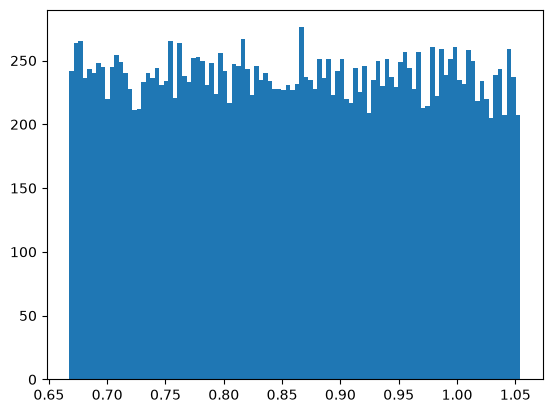

In [12]:
plt.hist(etas, bins=100);

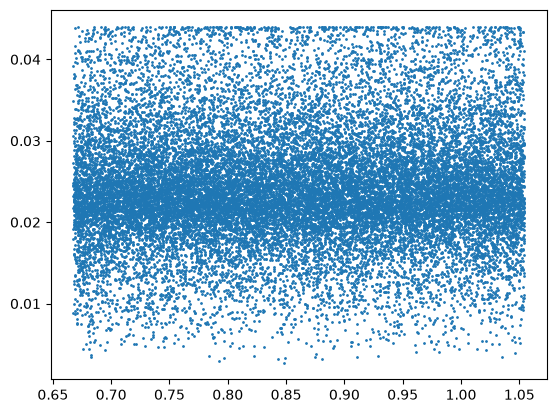

In [29]:
plt.scatter(etas, Pdecays, s=1);

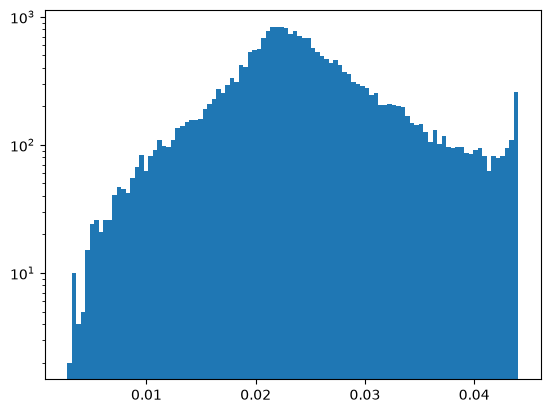

In [31]:
plt.hist(Pdecays, bins=100, log=1);

# Generate LLPs

In [31]:
reload(generator)

<module 'simhelper.generator' from '/project/6035200/tomren/jupyter/mathusla-newsim/tests/filereader_generator/../../python/simhelper/generator.py'>

In [33]:

N_MC = 10_000
rand_seed = 1
nprint=2000

for ctau in [1,3,10,30,100,300,1000,3000,10000]:  # in mm 
    print(f"---------------ctau={ctau} m-----------------")
    for mX in [15,25,35,45,55]:
        print(f"---------------mX={mX} GeV-----------------")
        filename_llp4vec = f"{DATA_DIR}/0_decay_files_raw/MATHUSLA_LLPfiles_HXX/All_HXX_LLP4vectors/HXX_LLP4vectors_mX_{mX}_2perevent_unweighted.csv"
        filename_products = f"{DATA_DIR}/0_decay_files_raw/MATHUSLA_LLPfiles_HXX/H_hadronic_decays_geant/bb_{mX}.txt"
        filename_output = f"{DATA_DIR}/1_decay_files_transformed_V2/MATHUSLA_LLPfiles_HXX/LLP_bb_{mX}_ctau_{ctau}.root"  
        # if os.path.exists(filename_output):
        #     continue
        vec_used = generator.gen_llp(filename_llp4vec, filename_products, filename_output, mX, ctau, N_MC, rand_seed=1, nprint=nprint,metadata=None)
    #     break
    # break

---------------ctau=1 m-----------------
---------------mX=15 GeV-----------------
Reading LLP 4-vector file
  167284 4-vectors
Reading LLP decay product file
  19999 LLP decay events
Calculating kinematics of 4vecs
  Number of 4vectors 24796
Selecting 10000 events out of 19999
  Processed 2000 events
  Processed 4000 events
  Processed 6000 events
  Processed 8000 events
  Processed 10000 events
   Number of unique 4-vec: 685
---------------mX=25 GeV-----------------
Reading LLP 4-vector file
  167284 4-vectors
Reading LLP decay product file
  19999 LLP decay events
Calculating kinematics of 4vecs
  Number of 4vectors 23830
Selecting 10000 events out of 19999
  Processed 2000 events
  Processed 4000 events
  Processed 6000 events
  Processed 8000 events
  Processed 10000 events
   Number of unique 4-vec: 289
---------------mX=35 GeV-----------------
Reading LLP 4-vector file
  167284 4-vectors
Reading LLP decay product file
  19999 LLP decay events
Calculating kinematics of 4vecs
  Nu

# Check result

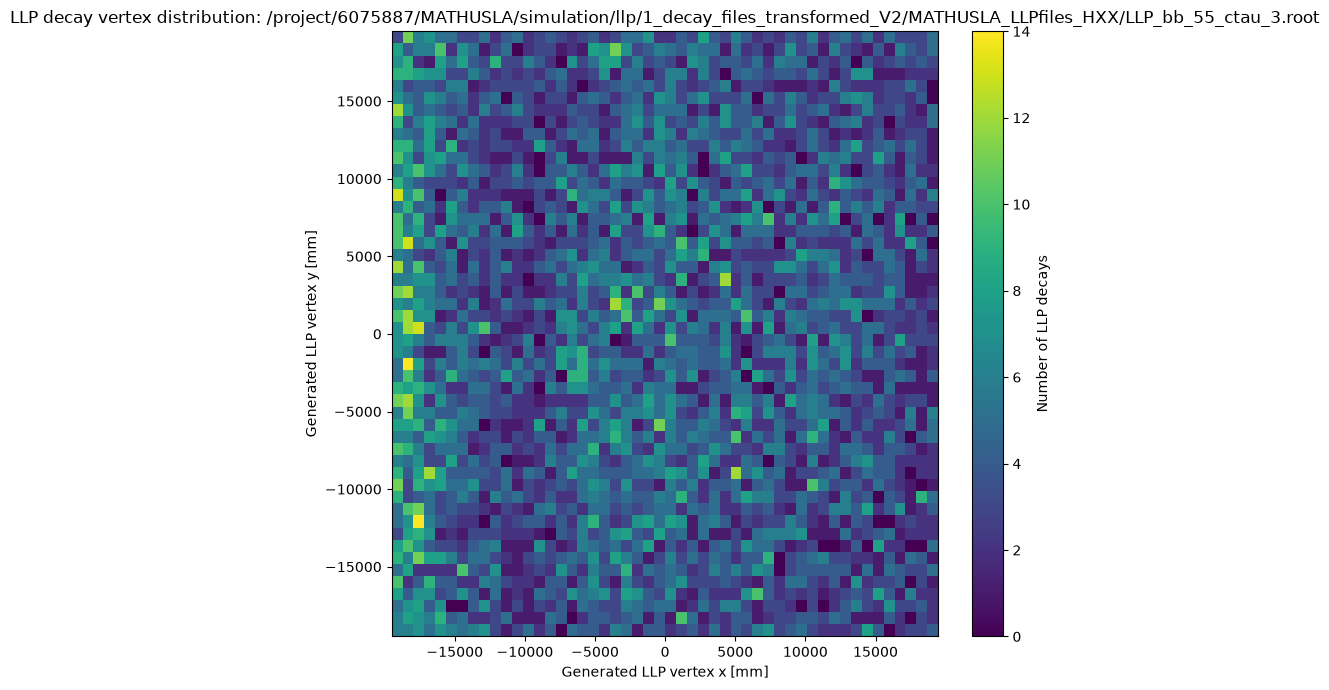

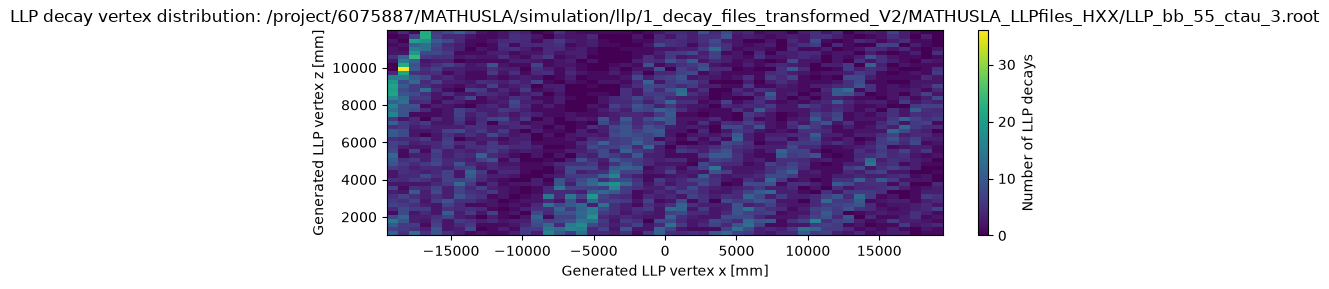

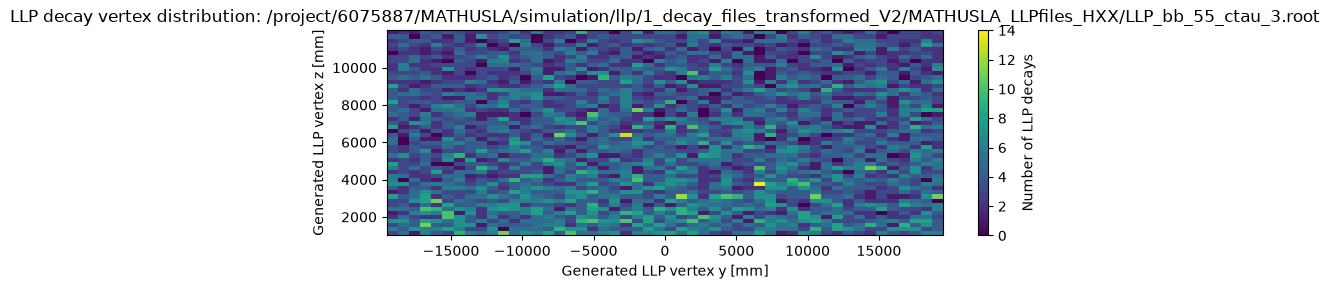

In [38]:
import argparse
import numpy as np
import uproot
import matplotlib.pyplot as plt

# parser = argparse.ArgumentParser()
# parser.add_argument("filename", help="Generated LLP ROOT file")
# parser.add_argument("--bins", type=int, default=100)
# args = parser.parse_args()
class args:
    filename = "/project/6075887/MATHUSLA/simulation/llp/1_decay_files_transformed_V2/MATHUSLA_LLPfiles_HXX/LLP_bb_55_ctau_3.root"
    bins = 50


tree = uproot.open(args.filename)["data"]

# Each decay product repeats the LLP vertex. Use only the first particle
# from each event so each LLP decay is counted once.
x_events = tree["Gen_x"].array(library="np")
y_events = tree["Gen_y"].array(library="np")

x = np.array([event[0] for event in x_events if len(event) > 0], dtype=float)
y = np.array([event[0] for event in y_events if len(event) > 0], dtype=float)

mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

plt.figure(figsize=(8, 7))
plt.hist2d(x, y, bins=args.bins, cmap="viridis")
plt.colorbar(label="Number of LLP decays")

plt.xlabel("Generated LLP vertex x [mm]")
plt.ylabel("Generated LLP vertex y [mm]")
plt.title(f"LLP decay vertex distribution: {args.filename}")
# plt.gca().set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()


# Each decay product repeats the LLP vertex. Use only the first particle
# from each event so each LLP decay is counted once.
x_events = tree["Gen_x"].array(library="np")
y_events = tree["Gen_z"].array(library="np")

x = np.array([event[0] for event in x_events if len(event) > 0], dtype=float)
y = np.array([event[0] for event in y_events if len(event) > 0], dtype=float)

mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

plt.figure(figsize=(8, 3))
plt.hist2d(x, y, bins=args.bins, cmap="viridis")
plt.colorbar(label="Number of LLP decays")

plt.xlabel("Generated LLP vertex x [mm]")
plt.ylabel("Generated LLP vertex z [mm]")
plt.title(f"LLP decay vertex distribution: {args.filename}")
# plt.gca().set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()


# Each decay product repeats the LLP vertex. Use only the first particle
# from each event so each LLP decay is counted once.
x_events = tree["Gen_y"].array(library="np")
y_events = tree["Gen_z"].array(library="np")

x = np.array([event[0] for event in x_events if len(event) > 0], dtype=float)
y = np.array([event[0] for event in y_events if len(event) > 0], dtype=float)

mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

plt.figure(figsize=(8, 3))
plt.hist2d(x, y, bins=args.bins, cmap="viridis")
plt.colorbar(label="Number of LLP decays")

plt.xlabel("Generated LLP vertex y [mm]")
plt.ylabel("Generated LLP vertex z [mm]")
plt.title(f"LLP decay vertex distribution: {args.filename}")
# plt.gca().set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()